In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

processed_path = Path("../data/processed")

feature_data = pd.read_csv(
    processed_path / "daily_features.csv"
)

feature_data["date"] = pd.to_datetime(
    feature_data["date"]
)

evaluation_data = feature_data[
    feature_data["day_number"] > 7
].copy()

print("Evaluation shape:", evaluation_data.shape)

Evaluation shape: (74, 21)


In [2]:
from sklearn.ensemble import IsolationForest

model_features = [
    "steps_deviation_7d_pct",
    "sleep_deviation_7d_pct"
]

X = evaluation_data[model_features].copy()

model = IsolationForest(
    n_estimators=100,
    contamination="auto",
    random_state=42
)

model.fit(X)

evaluation_data["anomaly_label"] = model.predict(X)
evaluation_data["anomaly_score"] = model.decision_function(X)

print(evaluation_data["anomaly_label"].value_counts())

anomaly_label
 1    55
-1    19
Name: count, dtype: int64


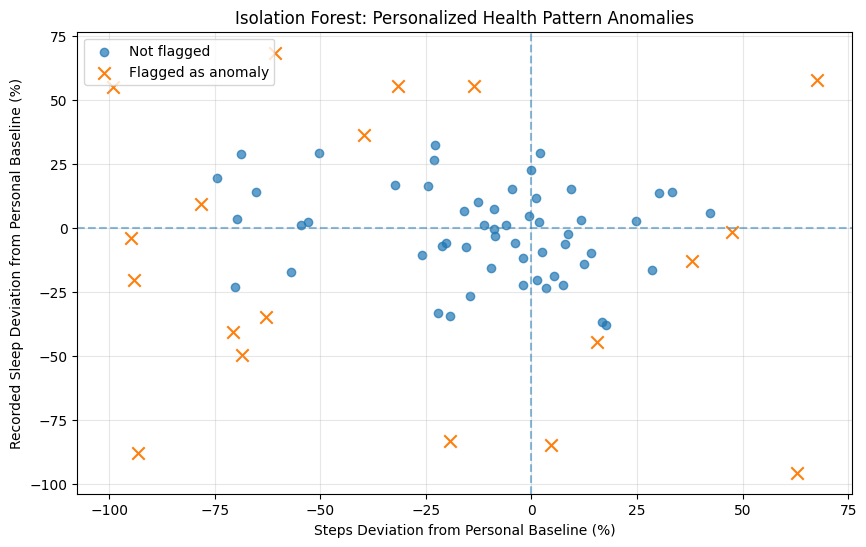

In [3]:
normal = evaluation_data[
    evaluation_data["anomaly_label"] == 1
]

anomalies = evaluation_data[
    evaluation_data["anomaly_label"] == -1
]

plt.figure(figsize=(10, 6))

plt.scatter(
    normal["steps_deviation_7d_pct"],
    normal["sleep_deviation_7d_pct"],
    label="Not flagged",
    alpha=0.7
)

plt.scatter(
    anomalies["steps_deviation_7d_pct"],
    anomalies["sleep_deviation_7d_pct"],
    label="Flagged as anomaly",
    marker="x",
    s=80
)

plt.axvline(0, linestyle="--", alpha=0.5)
plt.axhline(0, linestyle="--", alpha=0.5)

plt.xlabel("Steps Deviation from Personal Baseline (%)")
plt.ylabel("Recorded Sleep Deviation from Personal Baseline (%)")
plt.title("Isolation Forest: Personalized Health Pattern Anomalies")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [4]:
top_anomalies = evaluation_data.sort_values(
    "anomaly_score"
).head(10)

display(
    top_anomalies[
        [
            "Id",
            "date",
            "steps_deviation_7d_pct",
            "sleep_deviation_7d_pct",
            "anomaly_score"
        ]
    ]
)

,Id,date,steps_deviation_7d_pct,sleep_deviation_7d_pct,anomaly_score
51,2347167796,2016-04-09,62.925707,-95.549339,-0.236835
115,4702921684,2016-04-09,67.628397,57.893258,-0.202775
176,7086361926,2016-04-10,-93.127545,-87.755102,-0.184810
27,1927972279,2016-04-12,-99.220237,54.885923,-0.151869
26,1927972279,2016-04-11,-60.719424,68.445975,-0.124013
78,4020332650,2016-04-10,-19.357157,-83.338694,-0.109558
49,2347167796,2016-04-07,4.557757,-84.689725,-0.105868
178,7086361926,2016-04-12,-94.806405,-3.854875,-0.069200
101,4445114986,2016-04-12,-94.208506,-20.239219,-0.065733
190,8378563200,2016-04-12,-68.580871,-49.413690,-0.062663


In [5]:
top_anomalies = evaluation_data.sort_values(
    "anomaly_score"
).head(10)

display(
    top_anomalies[
        [
            "Id",
            "date",
            "TotalSteps",
            "baseline_steps_7d",
            "recorded_sleep_minutes",
            "baseline_sleep_7d",
            "steps_deviation_7d_pct",
            "sleep_deviation_7d_pct",
            "anomaly_score"
        ]
    ]
)

,Id,date,TotalSteps,baseline_steps_7d,recorded_sleep_minutes,baseline_sleep_7d,steps_deviation_7d_pct,sleep_deviation_7d_pct,anomaly_score
51,2347167796,2016-04-09,16081,9870.142857,25,561.714286,62.925707,-95.549339,-0.236835
115,4702921684,2016-04-09,14002,8353.000000,803,508.571429,67.628397,57.893258,-0.202775
176,7086361926,2016-04-10,569,8279.428571,54,441.000000,-93.127545,-87.755102,-0.184810
27,1927972279,2016-04-12,24,3077.857143,514,331.857143,-99.220237,54.885923,-0.151869
26,1927972279,2016-04-11,1209,3077.857143,559,331.857143,-60.719424,68.445975,-0.124013
78,4020332650,2016-04-10,5129,6360.142857,74,444.142857,-19.357157,-83.338694,-0.109558
49,2347167796,2016-04-07,10320,9870.142857,86,561.714286,4.557757,-84.689725,-0.105868
178,7086361926,2016-04-12,430,8279.428571,424,441.000000,-94.806405,-3.854875,-0.069200
101,4445114986,2016-04-12,278,4800.142857,362,453.857143,-94.208506,-20.239219,-0.065733
190,8378563200,2016-04-12,3246,10331.285714,265,523.857143,-68.580871,-49.413690,-0.062663


In [6]:
# Flag unusually low recorded sleep for manual review
evaluation_data["sleep_quality_review"] = (
    evaluation_data["recorded_sleep_minutes"] < 120
)

print(
    "Observations flagged for sleep-data review:",
    evaluation_data["sleep_quality_review"].sum()
)

display(
    evaluation_data.loc[
        evaluation_data["sleep_quality_review"],
        [
            "Id",
            "date",
            "recorded_sleep_minutes",
            "baseline_sleep_7d",
            "sleep_deviation_7d_pct",
            "anomaly_score"
        ]
    ].head(15)
)

Observations flagged for sleep-data review: 4


,Id,date,recorded_sleep_minutes,baseline_sleep_7d,sleep_deviation_7d_pct,anomaly_score
49,2347167796,2016-04-07,86,561.714286,-84.689725,-0.105868
51,2347167796,2016-04-09,25,561.714286,-95.549339,-0.236835
78,4020332650,2016-04-10,74,444.142857,-83.338694,-0.109558
176,7086361926,2016-04-10,54,441.000000,-87.755102,-0.184810


In [7]:
# Count anomaly observations that also need sleep-data review
anomaly_mask = evaluation_data["anomaly_label"] == -1
review_mask = evaluation_data["sleep_quality_review"]

print("Total ML anomalies:", anomaly_mask.sum())

print(
    "Anomalies with low recorded sleep:",
    (anomaly_mask & review_mask).sum()
)

print(
    "Low-sleep review observations not flagged by ML:",
    ((~anomaly_mask) & review_mask).sum()
)

Total ML anomalies: 19
Anomalies with low recorded sleep: 4
Low-sleep review observations not flagged by ML: 0


In [8]:
participant_counts = evaluation_data.groupby("Id").size()

print("Unique participants:", evaluation_data["Id"].nunique())
print("\nObservations per participant:")
print(participant_counts.sort_values(ascending=False))

Unique participants: 15

Observations per participant:
Id
4020332650    8
2347167796    7
1503960366    7
6962181067    7
4702921684    7
2026352035    5
5553957443    5
8378563200    5
4445114986    5
3977333714    4
5577150313    4
4319703577    3
1927972279    3
7086361926    3
8792009665    1
dtype: int64


## Day 10 — Data Quality and Evaluation Findings

- Inspected the 10 lowest anomaly-score observations using raw activity, recorded sleep and personal baseline values.
- Identified 4 evaluation observations with recorded sleep below the exploratory 120-minute review threshold.
- All 4 low-recorded-sleep observations were also flagged by Isolation Forest.
- The evaluation subset contains 15 participants with unequal observation counts, ranging from 1 to 8 observations.
- Clinical outcome labels are unavailable; anomaly flags do not establish disease or health deterioration.
- Future evaluation should account for participant-level separation, limited observations and potential data-quality issues.